<a href="https://colab.research.google.com/github/joiepark/assignment_esaa/blob/main/261102_%ED%95%A9%EC%84%B1%EA%B3%B1%EC%8B%A0%EA%B2%BD%EB%A7%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 합성곱 신경망 I

## 합성곱 신경망

*   문제 상황: 딥러닝의 역전파는 순전파 과정에 따라 계산된 오차 정보가 신경망의 모든 노드(출력층→은닉층→입력층)로 전송되는데, 이 계산 과정에서 많은 자원과 시간이 요구됨. 이미지 분석은 배열을 펼쳐서 각 픽셀에 가중치를 곱해 은닉층으로 전달되는 방식을 사용하는데, 이 때 데이터의 공간적 구조를 무시하게 됨.
*   합성곱 신경망(**Convolutional Neural Network**, CNN 또는 ConvNet)은 음성 인식이나 이미지/영상 인식에서 주로 사용되는 신경망임. 다차원 배열 데이터를 처리하도록 구성되어 컬러 이미지 같은 다차원 배열 처리에 특화됨. 입력층, 합성곱층, 풀링층, 완전연결층, 출력층 총 다섯 개의 계층으로 구성됨,

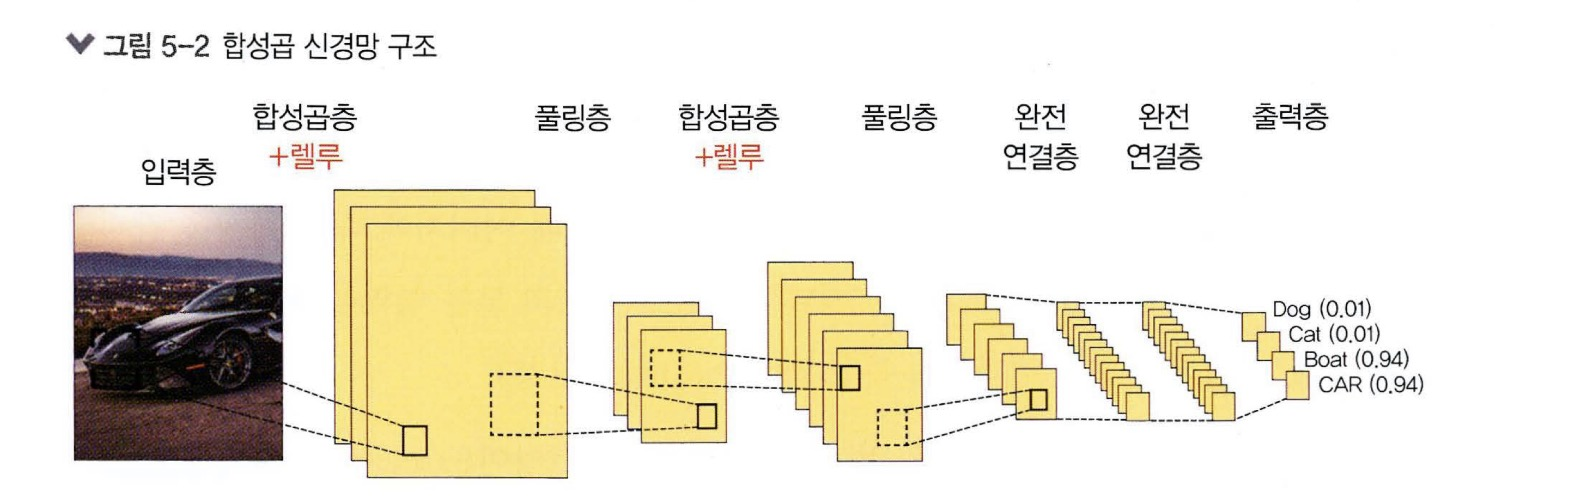




*   합성곱 신경망은 **합성곱층과 풀링층을 거치며 입력 이미지의 주요 특성 벡터(feature vector)를 추출**함. 추출된 주요 특성 벡터들은 **완전 연결층을 거치며 1차원 벡터로 변환**됨. 마지막으로 **출력층에서 활성화 함수인 소프트맥스(softmax) 함수를 사용해 최종 결과를 출력**함.

## 입력층


*   입력층(input layer)은 **입력 이미지 데이터가 최초로 거치게 되는 계층**임. **이미지는 단순 1차원 데이터가 아닌 높이, 너비, 채널의 값을 갖는 3차원 데이터**임. (* 채널은 이미지가 그레이스케일(gray scale)이면 1 값을, 컬러(RGB)이면 3 값을 가짐.) (e.g. 높이 4, 너비 4, 채널은 RGB일 때 이미지 형태는 (4, 4, 3))

## 합성곱층


*   합성곱층(convolutional layer)은 **입력 데이터에서 특성을 추출하는 역할**을 수행함. 입력 이미지가 들어왔을 때 이미지에 대한 특성을 감지하기 위해 커널(kernel)이나 필터를 사용하는데, **커널과 필터는 이미지의 모든 영역을 훑으며 특성을 추출하고 특성 맵(feature map)을 만듦**. (* 이 때 커널은 3x3, 5x5 크기로 적용되는 것이 일반적이며, 스트라이드(stride)라는 지정된 간격에 따라 순차적으로 이동함.)
*   그레이스케일에서 커널은 스트라이드 간격만큼 순회하면서 모든 입력 값과의 합성곱 연산으로 새로운 특성 맵을 만들며, 커널과 스트라이드의 상호 작용으로 원본 크기에 비해 줄어든 크기의 특성 맵이 생성됨.









*   그레이스케일 이미지에 대해 컬러 이미지가 구분되는 특징은 (1) 필터 채널이 3 (* 단, 필터 개수는 한 개) (2) RGB 각각에 서로 다른 가중치로 합성곱을 적용한 후 결과를 더해줌
*   필터가 두 개 이상인 합성곱은 동일한 방법으로 계산하되 필터 각각은 특성 추출 결과의 채널이 됨.

*   즉 합성곱층을 요약하면


1.   입력 데이터: W1 X H1 X D1 (W1: 가로, X H1: 세로, X D1: 채널 또는 깊이)
2.   하이퍼파라미터: K: 필터 개수, F: 필터 크기, S: 스트라이드, P: 패딩
3. 출력 데이터: W2 = (W1 - F + 2P)/S + 1, H2 = (H1 - F + 2P)/S + 1, D2 = K

### 풀링층
*   풀링층(pooling layer)은 합성곱층과 유사하게 **특성 맵의 차원을 다운 샘플링**해 연산량을 감소시키고, **주요한 특성 벡터를 추출**해 효과적인 학습을 가능케 함.

*   풀링 연산에는 대상 영역에서 최댓값을 추출하는 최대 풀링(max pooling)과 평균을 반환하는 평균 풀링(average pooling)이 있으며 **대부분의 합성곱 신경망에서는 최대 풀링이 사용됨**. 평균 풀링은 각 커널 값을 평균화시켜 중요한 가중치를 갖는 값의 특성이 희미해질 수 있음.
*   최대 풀링과 평균 풀링을 요약하면

1.   입력 데이터: W1 X H1 X D1
2.   하이퍼파라미터: 필터 크기: F, 스트라이드: S
3. 출력 데이터: W2 = (W1 - F)/S + 1, H2 = (H1 - F)/S + 1, D2 = D1









### 완전연결층


*   합성곱층과 풀링층을 거치며 차원이 축소된 특성 맵은 최종적으로 완전연결층으로 전달되는데, 이 과정에서 이미지는 3차원 벡터에서 1차원 벡터로 펼쳐지게 됨.
### 출력층
*   출력층(output layer)에서는 소프트맥스 활성화 함수가 사용되는데, 입력받은 값을 0~1 사이의 값으로 출력함. 따라서 **마지막 출력층의 소프트맥스 함수를 사용해 이미지가 각 레이블에 속할 확률 값이 출력되며, 이 때 가장 높은 확률 값을 갖는 레이블이 최종 값으로 선정**됨.

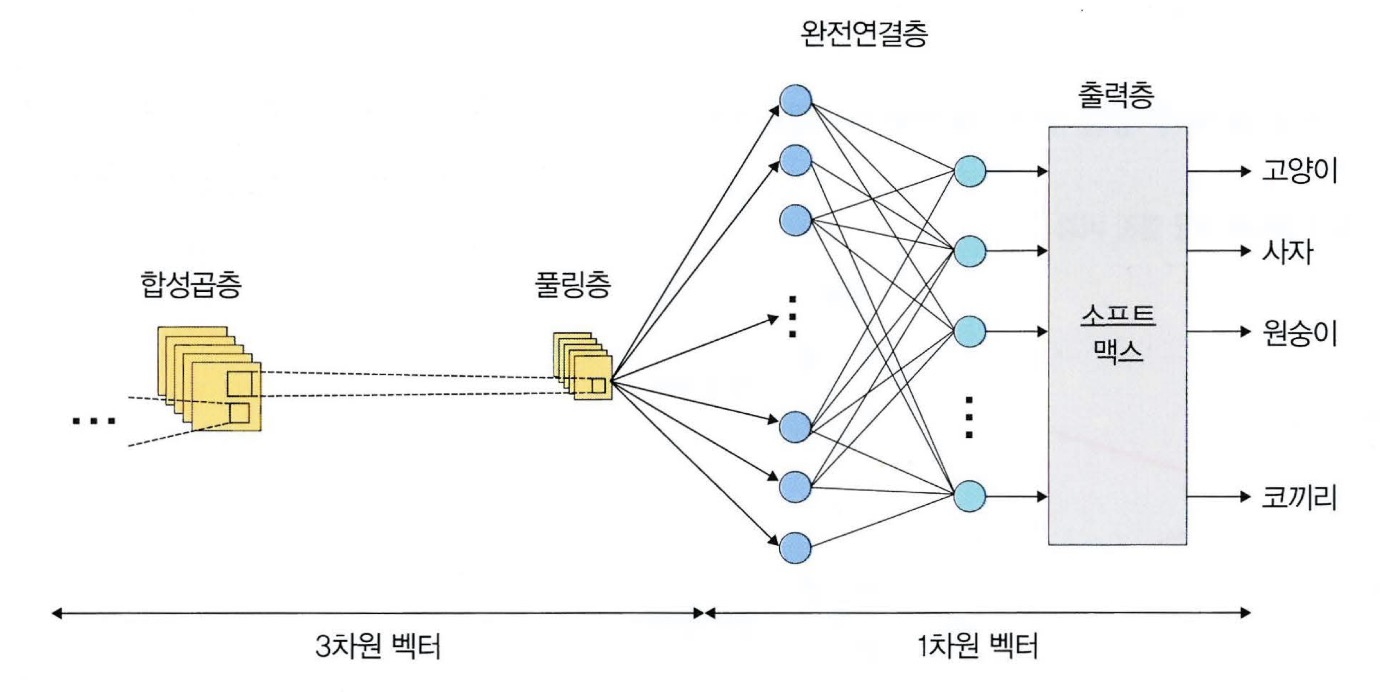

## 1D, 2D, 3D 합성곱

*   합성곱은 이동하는 방향의 수와 출력 형태에 따라 1D, 2D, 3D로 분류할 수 있음.
*   1D 합성곱은 필터가 시간을 축으로 좌우로만 이동할 수 있는 합성곱임. 따라서 입력(W)과 필터(k)에 대한 출력은 W가 됨. (e.g. 입력이 [1, 1, 1, 1, 1]이고 필터가 [0.25, 0.25, 0.25]라면 출력은 [1, 1, 1]) 출력 형태는 1D의 배열이 되며, 그래프 곡선을 완화할 때 자주 사용함.
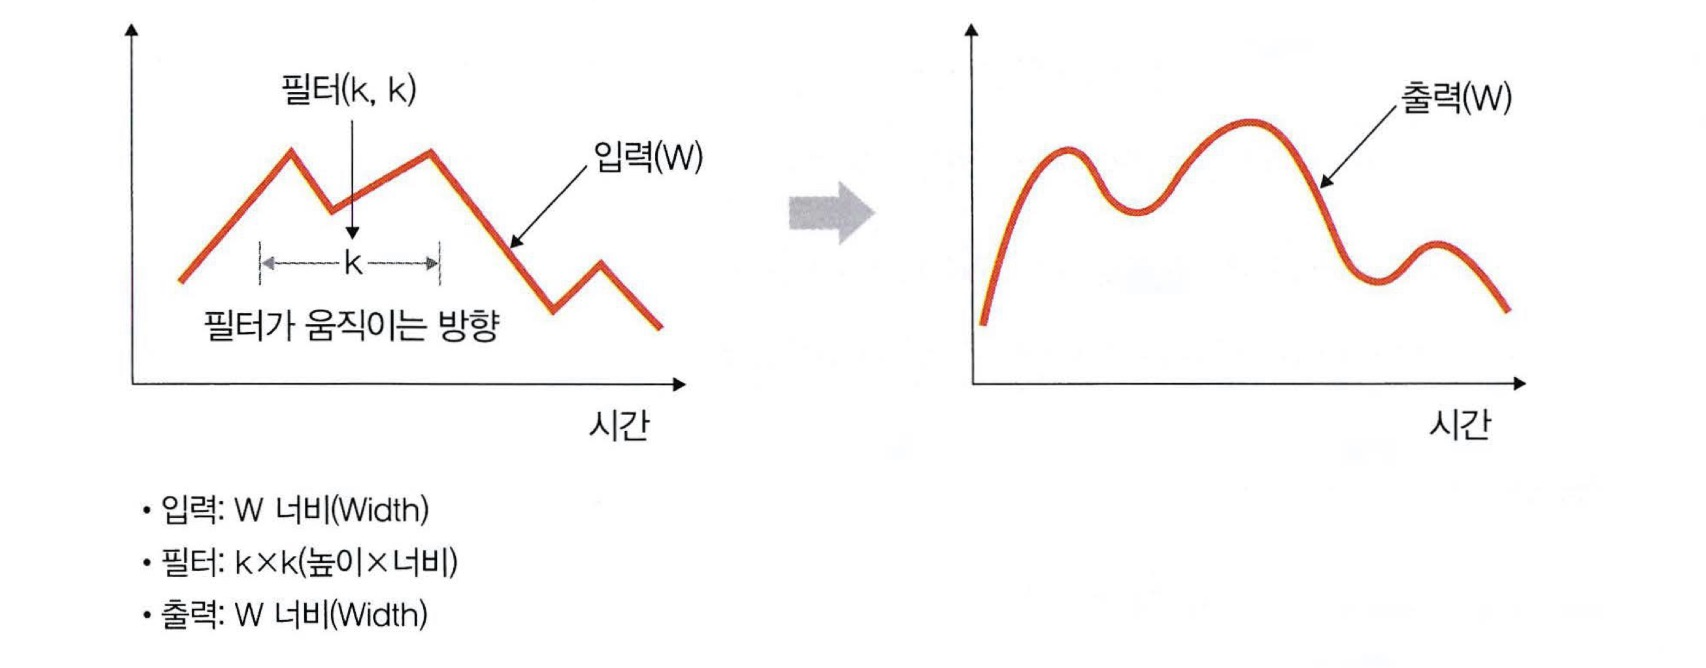






*   2D 합성곱은 필터가 방향 두 개로 움직이는 형태임. 즉, 입력(W, H)과 필터(k,k)에 대한 출력은 (W, H)가 되며 출력 형태는 2D 행렬임.
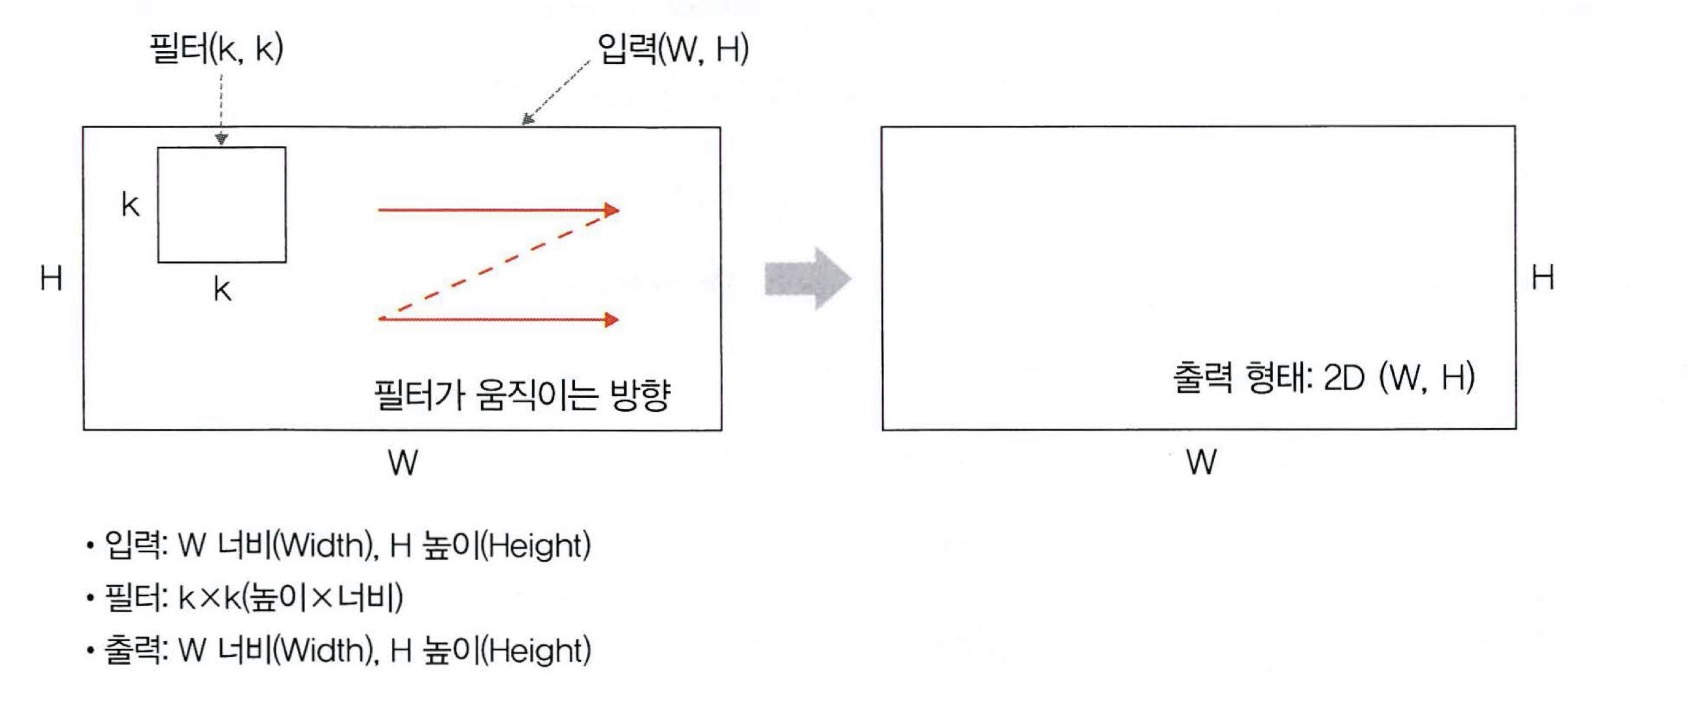



*   3D 합성곱은 필터가 움직이는 방향이 세 개 있음. 입력(W, H, L)에 대해 필터(k, k, d)를 적용하면 출력으로 (W, H, L)을 갖는 형태임. 출력은 3D 형태이며, 이 때 d<L을 유지해야 함.
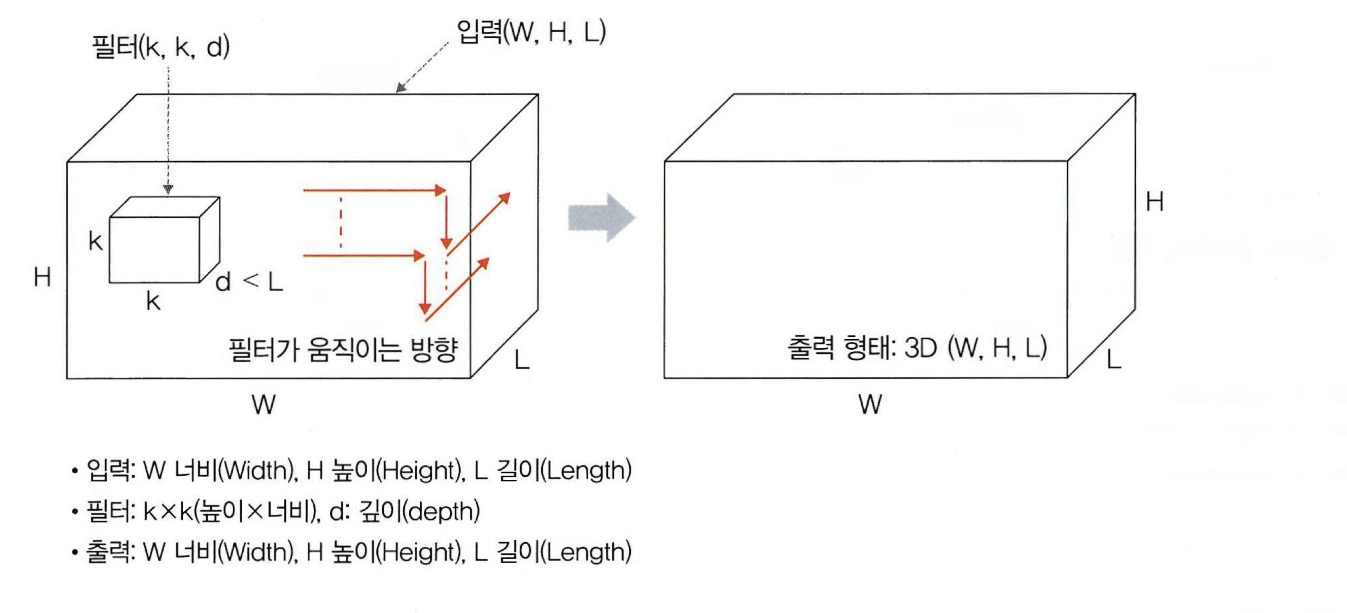



*   3D 입력을 갖는 2D 합성곱은 필터에 대한 길이(L)가 입력 채널의 길이(L)와 같아야 하기 때문에 이와 같은 합성곱 형태가 만들어짐. 즉, 입력(W, H, L)에 필터(k, k, L)를 적용하면 출력은 (W, H)가 됨. 이 때 필터는 두 방향으로 움직이며 출력 형태는 2D가 됨. 대표적 사례로는 LeNet-5와 VGG가 있음.
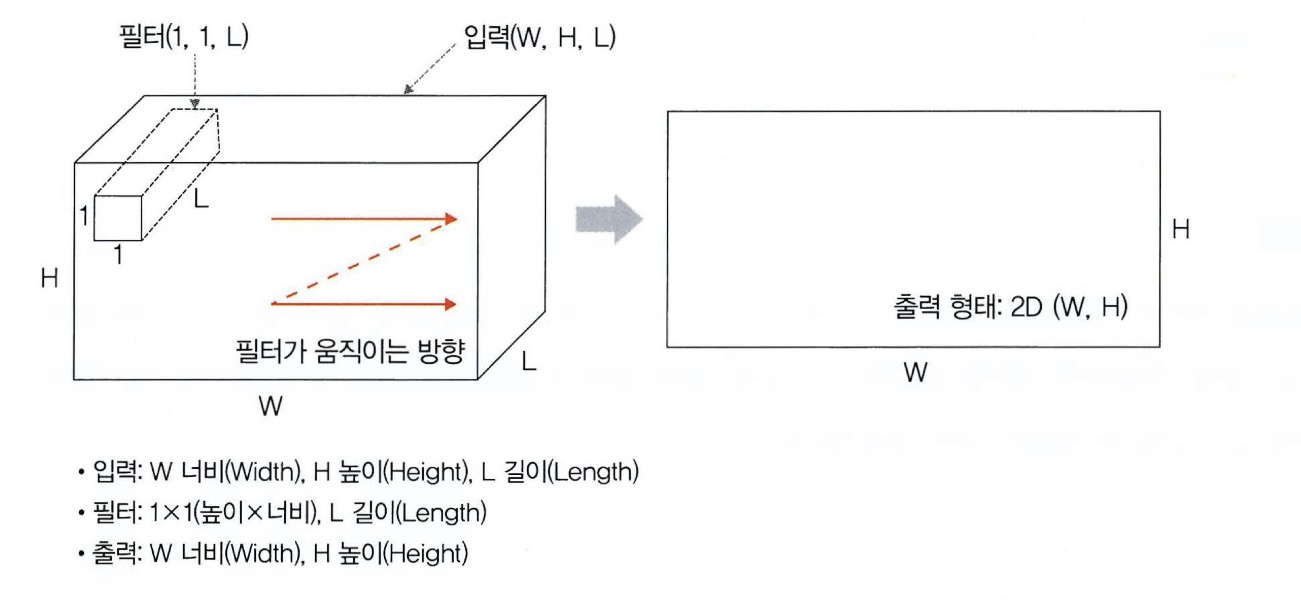





*   1 X 1 합성곱은 3D 형태로 입력됨. 즉, 입력(W, H, L)에 필터(1, 1, L)를 적용하면 출력은 (W, H)가 됨. 채널 수를 조정해 연산량을 감소시키는 효과가 있으며, 대표적 사례로는 GoogLeNet이 있음.
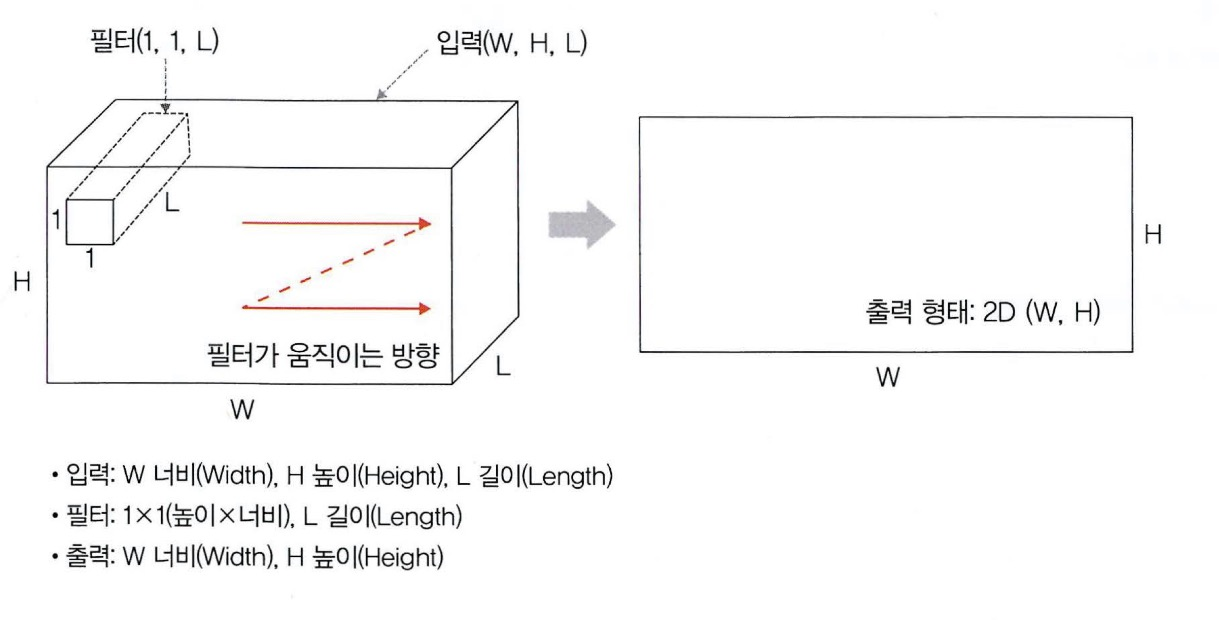

